# EV ChargeOps: evidências de funcionamento (Sprint 2)

Enterprise Challenge 2026, GoodWe + FIAP. Equipe: RM573133, RM571998, RM571913, RM568867, RM574003.

Este notebook executa o protótipo de ponta a ponta usando os mesmos módulos da aplicação (`src/model`, `src/controller`, `src/view`). Ele só lê a base de demonstração; nenhuma célula fecha mês ou grava sessão.

Roteiro:
1. Dados: as tabelas da Sprint 1 e as sessões registradas
2. Lógica central: consumo individual e rateio, com e sem taxa
3. Regras auxiliares: sessão interrompida, vários cartões, isenção e bloqueio
4. IA, frente 1: previsão de demanda e risco de sobrecarga
5. Alertas por prioridade e conciliação com o SEMS
6. IA, frente 2: Síndico Virtual
7. Indicadores definidos na Sprint 1

In [1]:
import os
import sys

# o notebook fica em notebooks/; os dados e o codigo ficam na raiz do repositorio
if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
sys.path.append("src")

import pandas as pd

from controller import controle_gestor, controle_ia, controle_morador, controle_sessao
from model import alertas, dados, ia_previsao, rateio, sindico_virtual, telemetria
from view import graficos
from formato import decimal, reais

controle_sessao.preparar_sistema()
print("Base de demonstração pronta. Meses com sessões:", dados.meses_com_sessoes())

Base de demonstração pronta. Meses com sessões: ['06-2026', '07-2026', '08-2026', '09-2026', '10-2026']


## 1. Dados: as seis tabelas da Sprint 1

O esquema do README da Sprint 1 (Unit, User, RFID_Card, Charger, Session, Invoice) foi mantido com os mesmos campos. Cada tabela é um arquivo JSON em `dados/`.

In [2]:
for nome in ("units", "users", "rfid_cards", "chargers", "sessions", "invoices"):
    tabela = dados.carregar_tabela(nome)
    print(f"{nome:<11} {len(tabela):>4} registros | exemplo: {tabela[0]}")

units          8 registros | exemplo: {'id': 1, 'name': 'Apto 42', 'block': 'Torre A'}
users         10 registros | exemplo: {'id': 101, 'unit_id': 1, 'name': 'João Silva', 'email': 'joao@email.com'}
rfid_cards    10 registros | exemplo: {'uid': 'A1B2C3D4', 'user_id': 101, 'status': True}
chargers       2 registros | exemplo: {'id': 'GW-001', 'model': 'GW7K-HCA', 'max_power_kw': 7.0, 'location': 'Vaga L1'}
sessions     288 registros | exemplo: {'id': 5001, 'rfid_uid': 'A1B2C3D4', 'charger_id': 'GW-001', 'start_time': '2026-06-18 19:00', 'end_time': '2026-06-18 22:30', 'kwh_delivered': 21.5, 'potencia_media_kw': 6.14, 'pico_kw': 6.51, 'interrompida': False}
invoices      32 registros | exemplo: {'id': 9001, 'unit_id': 1, 'month': '06-2026', 'total_kwh': 120.0, 'total_value': 114.0, 'status': 'PAID', 'tarifa': 0.95, 'taxa_admin': 0.0, 'sessoes': 6, 'fechado_em': '2026-07-01', 'vencimento': '2026-07-31', 'pago_em': '2026-07-10'}


Os registros de exemplo do README da Sprint 1 existem na base com os mesmos valores: Apto 42 / Torre A, João Silva, cartão `A1B2C3D4`, carregador `GW-001`, sessão `5001` e fatura `9001`.

In [3]:
print("Sessão 5001:", dados.buscar(dados.carregar_tabela("sessions"), "id", 5001))
print("Fatura 9001:", dados.buscar(dados.carregar_tabela("invoices"), "id", 9001))

Sessão 5001: {'id': 5001, 'rfid_uid': 'A1B2C3D4', 'charger_id': 'GW-001', 'start_time': '2026-06-18 19:00', 'end_time': '2026-06-18 22:30', 'kwh_delivered': 21.5, 'potencia_media_kw': 6.14, 'pico_kw': 6.51, 'interrompida': False}
Fatura 9001: {'id': 9001, 'unit_id': 1, 'month': '06-2026', 'total_kwh': 120.0, 'total_value': 114.0, 'status': 'PAID', 'tarifa': 0.95, 'taxa_admin': 0.0, 'sessoes': 6, 'fechado_em': '2026-07-01', 'vencimento': '2026-07-31', 'pago_em': '2026-07-10'}


In [4]:
sessoes = ia_previsao.exportar_sessoes_csv()
print("Sessões no histórico:", len(sessoes))
sessoes.head(8)

Sessões no histórico: 288


,session_id,unit_id,rfid_uid,charger_id,data,hora_inicio,dia_semana,duracao_min,kwh,potencia_media_kw,pico_kw,interrompida
0,5002,1,A1B2C3D4,GW-001,2026-06-01,19,0,170,17.20,6.07,6.43,0
1,5007,3,D4E5F6A7,GW-002,2026-06-01,20,0,148,11.86,4.81,5.19,0
2,5008,6,B8C9D0E1,GW-001,2026-06-01,22,0,239,25.22,6.33,6.82,0
3,5009,5,F6A7B8C9,GW-002,2026-06-02,15,1,215,21.12,5.89,6.36,0
4,5010,8,D0E1F2A3,GW-001,2026-06-02,20,1,230,22.62,5.90,6.36,0
5,5011,3,D4E5F6A7,GW-002,2026-06-03,11,2,212,23.12,6.54,7.00,0
6,5012,5,F6A7B8C9,GW-002,2026-06-03,18,2,193,18.27,5.68,6.13,0
7,5013,6,A7B8C9D0,GW-001,2026-06-03,21,2,134,13.17,5.90,6.36,0


## 2. Lógica central: consumo individual e rateio

Modelo pay-per-use da Sprint 1:

**Fatura = Σ(E_sessao × T) + Tx_admin**

A tarifa `T` e a taxa `Tx_admin` ficam em `dados/config.json`. O fechamento do mês pode ser feito **sem taxa** ou **com taxa**.

In [5]:
config = dados.carregar_config()
print("Tarifa:", reais(config["tarifa_kwh"]), "por kWh | Taxa administrativa:", reais(config["taxa_admin"]))

for cenario in controle_gestor.cenarios_de_rateio():
    s = controle_gestor.simular_rateio(cenario["kwh"], cenario["tarifa"], cenario["taxa"])
    print()
    print(cenario["nome"])
    print("  consumo.........:", decimal(s["kwh"], 2), "kWh x", reais(s["tarifa"]), "=", reais(s["consumo"]))
    print("  opção SEM taxa..:", reais(s["total_sem_taxa"]))
    print("  opção COM taxa..:", reais(s["total_com_taxa"]))

Tarifa: R$ 0,95 por kWh | Taxa administrativa: R$ 2,00

Exemplo da Sprint 1 (fatura 9001)
  consumo.........: 120,00 kWh x R$ 0,95 = R$ 114,00
  opção SEM taxa..: R$ 114,00
  opção COM taxa..: R$ 114,00

Exemplo do pitch (Apto 42)
  consumo.........: 12,40 kWh x R$ 0,95 = R$ 11,78
  opção SEM taxa..: R$ 11,78
  opção COM taxa..: R$ 13,78


### Fatura 9001 do Apto 42 (junho de 2026)

A auditoria refaz a conta a partir das sessões gravadas e compara com o valor armazenado. Gestor e morador usam a mesma função, por isso veem a mesma composição.

In [6]:
auditoria = rateio.auditar_fatura(9001)
print("Total gravado....:", reais(auditoria["fatura"]["total_value"]))
print("Total recalculado:", reais(auditoria["valor_recalculado"]))
print("Energia..........:", decimal(auditoria["kwh_recalculado"], 2), "kWh")
print("Confere..........:", auditoria["confere"])
pd.DataFrame(auditoria["detalhe"])

Total gravado....: R$ 114,00
Total recalculado: R$ 114,00
Energia..........: 120,00 kWh
Confere..........: True


,sessao,inicio,fim,cartao,carregador,kwh,valor,interrompida
0,5002,2026-06-01 19:30,2026-06-01 22:20,A1B2C3D4,GW-001,17.2,16.34,False
1,5003,2026-06-08 20:00,2026-06-08 23:10,A1B2C3D4,GW-001,19.8,18.81,False
2,5004,2026-06-10 18:45,2026-06-10 21:50,A1B2C3D4,GW-001,18.5,17.57,False
3,5001,2026-06-18 19:00,2026-06-18 22:30,A1B2C3D4,GW-001,21.5,20.43,False
4,5005,2026-06-22 19:15,2026-06-22 22:35,A1B2C3D4,GW-001,20.4,19.38,False
5,5006,2026-06-24 20:10,2026-06-24 23:50,B2C3D4E5,GW-001,22.6,21.47,False


### Consolidado mensal

Mês fechado: uma linha por unidade. Mês aberto: a prévia mostra as duas opções de fechamento lado a lado.

In [7]:
pd.DataFrame(controle_gestor.consolidado_do_mes("09-2026"))

,fatura,unidade,bloco,sessoes,kwh,tarifa,taxa,total,status,vencimento
0,9025,Apto 42,Torre A,13,187.90,0.95,0.0,178.51,PAID,2026-10-31
1,9026,Apto 41,Torre A,11,188.76,0.95,0.0,179.32,PAID,2026-10-31
2,9027,Apto 32,Torre A,8,128.64,0.95,0.0,122.21,PENDING,2026-10-31
3,9028,Apto 31,Torre A,2,31.93,0.95,0.0,30.33,PAID,2026-10-31
4,9029,Apto 22,Torre B,12,201.57,0.95,0.0,191.49,PAID,2026-10-31
5,9030,Apto 21,Torre B,15,247.64,0.95,0.0,235.26,PAID,2026-10-31
6,9031,Apto 12,Torre B,0,0.00,0.95,0.0,0.00,ISENTO,2026-10-31
7,9032,Apto 11,Torre B,7,108.15,0.95,0.0,102.74,PAID,2026-10-31


In [8]:
previa = controle_gestor.previa_do_mes("10-2026")
print("Total SEM taxa:", reais(controle_gestor.total_da_coluna(previa, "total_sem_taxa")))
print("Total COM taxa:", reais(controle_gestor.total_da_coluna(previa, "total_com_taxa")))
pd.DataFrame(previa)

Total SEM taxa: R$ 277,06
Total COM taxa: R$ 291,06


,unidade,bloco,sessoes,kwh,total_sem_taxa,total_com_taxa
0,Apto 42,Torre A,4,54.03,51.33,53.33
1,Apto 41,Torre A,3,41.50,39.42,41.42
2,Apto 32,Torre A,0,0.00,0.00,0.00
3,Apto 31,Torre A,2,25.12,23.86,25.86
4,Apto 22,Torre B,3,54.76,52.02,54.02
5,Apto 21,Torre B,4,68.69,65.26,67.26
6,Apto 12,Torre B,2,28.71,27.27,29.27
7,Apto 11,Torre B,1,18.84,17.90,19.90


## 3. Telemetria e regras auxiliares

### Sessão de recarga simulada

O simulador reproduz o que o gateway leria do carregador GW7K-HCA: tensão e corrente a cada minuto, potência `P = V × I` e energia acumulada pelo método de Euler, `E[n+1] = E[n] + h × P[n]`. A célula abaixo só gera leituras; não grava sessão.

Resumo da sessão: {'kwh': 17.05, 'potencia_media_kw': 5.68, 'pico_kw': 6.12, 'duracao_min': 180}


,minuto,tensao_v,corrente_a,potencia_kw,energia_kwh
0,1,230.5,26.1,6.016,0.100
1,2,230.3,25.8,5.942,0.199
2,3,231.5,25.9,5.996,0.299
3,4,229.7,26.1,5.995,0.399
4,5,227.9,25.9,5.903,0.498


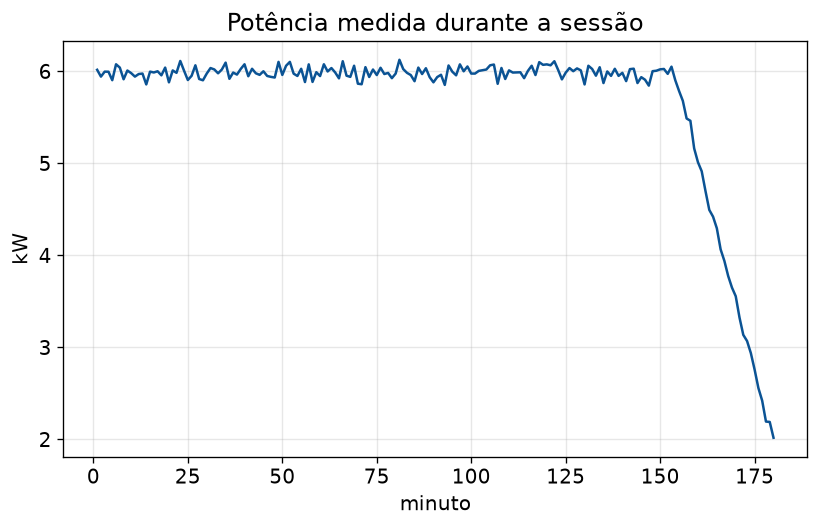

In [9]:
leituras = telemetria.simular_leituras(180, 26, -1)
resumo = telemetria.resumir_leituras(leituras)
print("Resumo da sessão:", resumo)
fig = graficos.grafico_potencia_da_sessao(leituras)
pd.DataFrame(leituras).head(5)

### Sessão interrompida

Uma queda no minuto 90 de uma sessão planejada para 180 minutos: a energia registrada é só a validada até a queda.

In [10]:
interrompida = telemetria.resumir_leituras(telemetria.simular_leituras(180, 26, 90))
print("Sessão interrompida:", interrompida)
print("Valor cobrado:", reais(interrompida["kwh"] * config["tarifa_kwh"]))

Sessão interrompida: {'kwh': 8.98, 'potencia_media_kw': 5.99, 'pico_kw': 6.13, 'duracao_min': 90}
Valor cobrado: R$ 8,53


### Vários cartões, isenção e bloqueio

In [11]:
print("Cartões do Apto 42 (somados na mesma fatura):")
for cartao in controle_morador.cartoes_da_unidade(1):
    print("  ", cartao)

isenta = dados.fatura_da_unidade(7, "09-2026")
print()
print("Apto 12 em 09-2026 (sem recarga):", isenta["status"], reais(isenta["total_value"]))

print()
print("Unidades com fatura vencida hoje:", [u["name"] for u in controle_gestor.unidades_inadimplentes()])
tentativa = telemetria.autorizar_cartao("D4E5F6A7", "GW-001", telemetria.proximo_horario_livre("GW-001"))
print("Tentativa com o cartão D4E5F6A7:", tentativa["autorizado"], "-", tentativa["motivo"])

Cartões do Apto 42 (somados na mesma fatura):
   {'uid': 'A1B2C3D4', 'usuario': 'João Silva', 'unit_id': 1, 'unidade': 'Apto 42', 'situacao': 'ativo'}
   {'uid': 'B2C3D4E5', 'usuario': 'Maria Silva', 'unit_id': 1, 'unidade': 'Apto 42', 'situacao': 'ativo'}

Apto 12 em 09-2026 (sem recarga): ISENTO R$ 0,00

Unidades com fatura vencida hoje: ['Apto 32']
Tentativa com o cartão D4E5F6A7: False - cartão bloqueado por fatura vencida


## 4. IA, frente 1: previsão de demanda e risco de sobrecarga

A série diária tem uma linha por dia. Entradas do modelo: tendência (`indice_dia`), uma coluna 0/1 para cada dia da semana (domingo é a referência), a energia de ontem e a média dos 7 dias anteriores.

In [12]:
tabela = ia_previsao.montar_tabela_diaria()
print("Dias no histórico:", len(tabela))
tabela.tail(8)

Dias no histórico:

 131


,data,indice_dia,dia_semana,fim_de_semana,kwh_total,n_sessoes,pico_kw,sobrecarga,kwh_ontem,kwh_media_7d,seg,ter,qua,qui,sex,sab
123,2026-10-02,123,4,0,25.92,2,5.24,0,26.31,33.79,0,0,0,0,1,0
124,2026-10-03,124,5,1,35.42,2,6.33,0,25.92,31.13,0,0,0,0,0,1
125,2026-10-04,125,6,1,0.00,0,0.00,0,35.42,33.92,0,0,0,0,0,0
126,2026-10-05,126,0,0,38.93,3,8.14,0,0.00,30.89,1,0,0,0,0,0
127,2026-10-06,127,1,0,42.41,2,6.55,0,38.93,27.89,0,1,0,0,0,0
128,2026-10-07,128,2,0,30.44,2,10.27,1,42.41,29.62,0,0,1,0,0,0
129,2026-10-08,129,3,0,58.24,4,11.31,1,30.44,28.49,0,0,0,1,0,0
130,2026-10-09,130,4,0,33.98,2,6.33,0,58.24,33.05,0,0,0,0,1,0


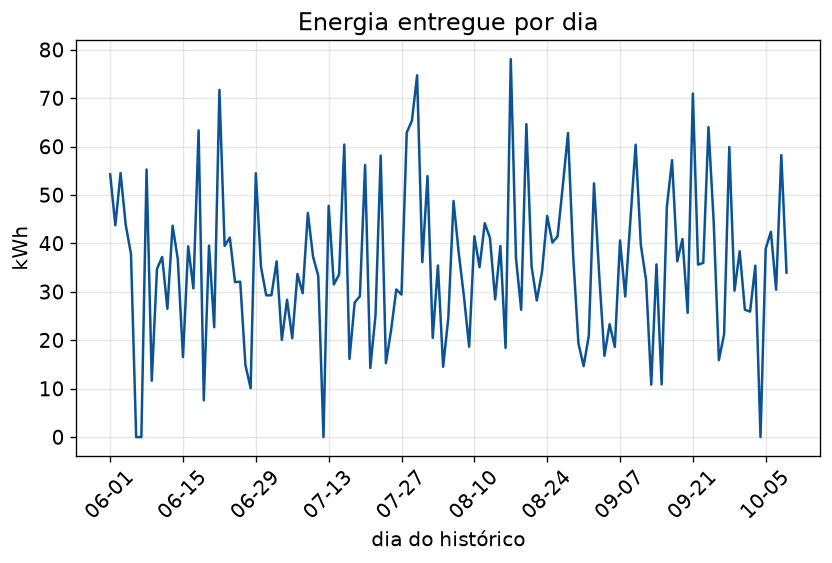

In [13]:
serie = controle_ia.serie_diaria()
fig = graficos.grafico_consumo_diario(serie["datas"], serie["kwh"])

### Treino e avaliação

Divisão temporal: o modelo treina nos primeiros 80% dos dias e é avaliado nos 20% finais (treina no passado, testa no futuro). São comparados uma regressão linear múltipla e um Ridge com `alpha` escolhido por `GridSearchCV` (cv = 5).

In [14]:
previsao = controle_ia.treinar()
print("Modelo escolhido:", previsao["modelo_escolhido"], "| melhor alpha do Ridge:", previsao["melhor_alpha"])
print("Dias de treino:", previsao["dias_treino"], "| dias de teste:", previsao["dias_teste"])
print("Precisão estimada (1 - erro relativo):", decimal(previsao["precisao_estimada"] * 100, 1) + "%")
pd.DataFrame([previsao["metricas_linear"], previsao["metricas_ridge"]], index=["Regressão Linear", "Ridge"])

Modelo escolhido: Regressão Linear | melhor alpha do Ridge: 1
Dias de treino: 104 | dias de teste: 27
Precisão estimada (1 - erro relativo): 74,3%


,mae,rmse,r2,erro_relativo
Regressão Linear,9.25,12.20,0.454,0.257
Ridge,9.34,12.27,0.448,0.259


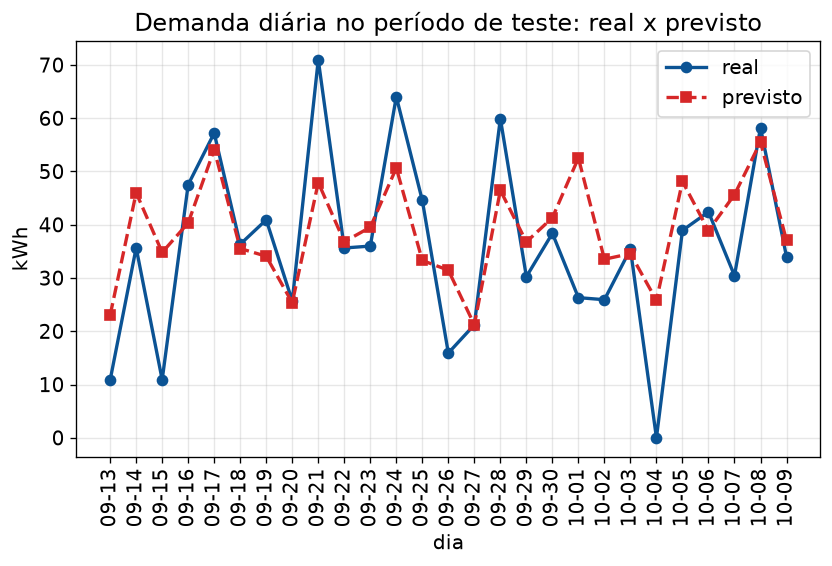

In [15]:
fig = graficos.grafico_previsao_vs_real(previsao["datas_teste"], previsao["y_teste"], previsao["y_previsto"])

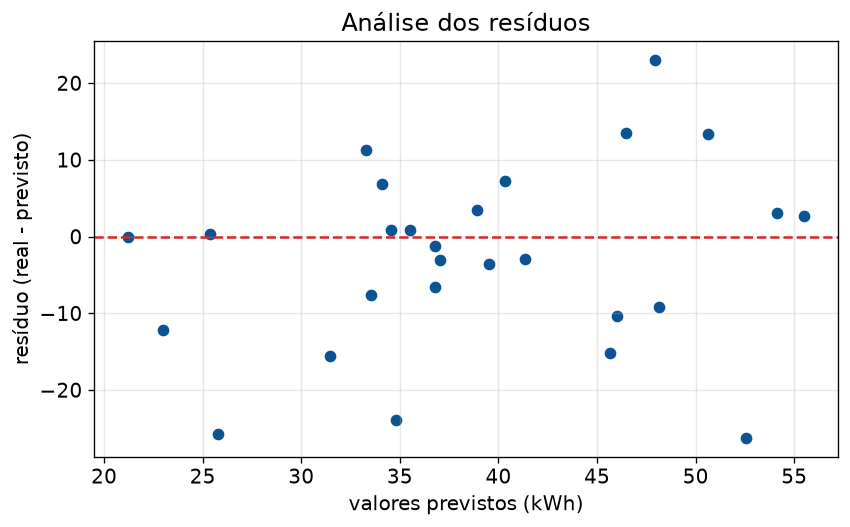

In [16]:
fig = graficos.grafico_residuos(previsao["y_teste"], previsao["y_previsto"])

### De onde vem o erro

O sistema compara o modelo com duas referências. O **teto do calendário** usa a média real de cada dia da semana, calculada com o histórico inteiro: é o máximo que um modelo baseado em calendário alcança nesses dados. A segunda referência supõe que a quantidade de recargas do dia é conhecida de antemão, como em um agendamento.

Modelo, por dia..............: 74,3%
Teto do calendário...........: 73,5%
Sabendo as recargas do dia...: 84,0%
Modelo, por semana...........: 88,8% (3 semanas de teste)
Média por recarga............: 16,2 kWh


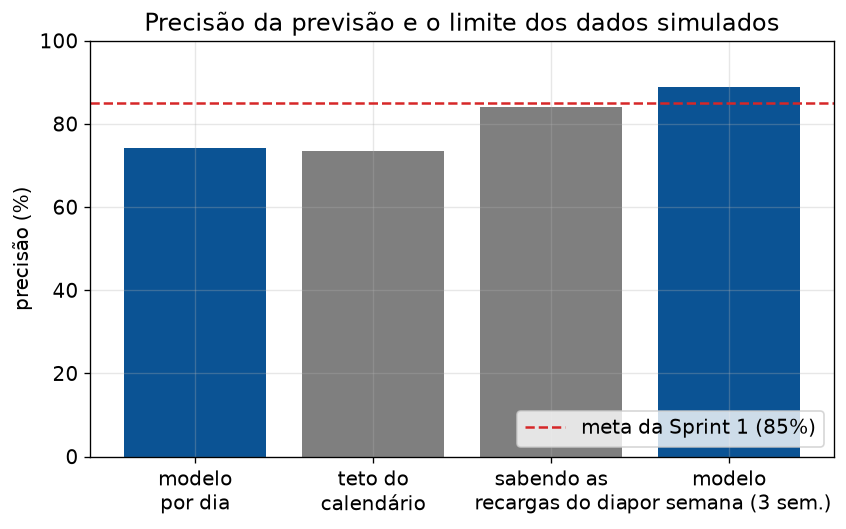

In [17]:
limite = previsao["analise_do_limite"]
print("Modelo, por dia..............:", decimal(limite["modelo_por_dia"] * 100, 1) + "%")
print("Teto do calendário...........:", decimal(limite["teto_do_calendario"] * 100, 1) + "%")
print("Sabendo as recargas do dia...:", decimal(limite["sabendo_as_recargas"] * 100, 1) + "%")
print("Modelo, por semana...........:", decimal(limite["modelo_por_semana"] * 100, 1) + "%",
      "(" + str(limite["semanas_de_teste"]) + " semanas de teste)")
print("Média por recarga............:", decimal(limite["media_kwh_por_recarga"], 1), "kWh")
fig = graficos.grafico_limite_dos_dados(limite, controle_ia.meta_de_precisao())

O modelo empata com o teto do calendário, então o erro que sobra não é do algoritmo: é a variação de quem recarrega e de quanto recarrega em cada dia. Só conhecer a quantidade de recargas já leva a precisão diária para perto da meta de 85%. Com dados reais chegando continuamente, o modelo é treinado de novo com mais histórico e pode usar esse tipo de informação.

### O que o modelo aprendeu

Ajuste de uma regressão linear simples sobre as mesmas colunas (sem os 7 primeiros dias, que não têm média móvel) para ler os coeficientes. Cada coeficiente de dia da semana é a diferença média, em kWh, em relação ao domingo.

In [18]:
from sklearn.linear_model import LinearRegression

validos = tabela[7:]
X = validos[ia_previsao.COLUNAS_DEMANDA].values
y = validos["kwh_total"].values
modelo = LinearRegression()
modelo.fit(X, y)
print("Intercepto (domingo, início do período):", round(modelo.intercept_, 2), "kWh")
for i in range(len(ia_previsao.COLUNAS_DEMANDA)):
    print(f"  {ia_previsao.COLUNAS_DEMANDA[i]:<14} {modelo.coef_[i]:>8.2f}")

Intercepto (domingo, início do período): 24.22 kWh
  indice_dia         0.04
  seg               25.74
  ter               10.20
  qua               17.25
  qui               29.64
  sex               10.03
  sab               11.30
  kwh_ontem          0.06
  kwh_media_7d      -0.24


### Curva de carga e janela de recarga

A curva de carga é uma matriz 7 × 24 com a potência média por dia da semana e hora. A sugestão de janela varre as horas e fica com a de menor demanda.

segunda  noite: 23h às 2h | dia: 6h às 9h | pico às 21h (7,8 kW)
quinta   noite: 23h às 2h | dia: 6h às 9h | pico às 21h (8,4 kW)
domingo  noite: 23h às 2h | dia: 6h às 9h | pico às 18h (2,5 kW)


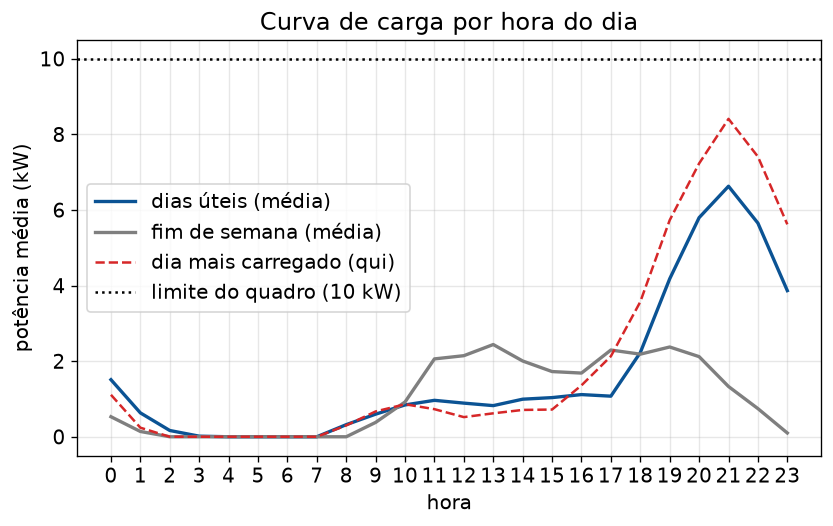

In [19]:
fig = graficos.grafico_curva_de_carga(previsao["curva_de_carga"], previsao["limite_quadro_kw"])
for dia in (0, 3, 6):
    j = ia_previsao.sugerir_janela(previsao["curva_de_carga"], dia, 3)
    print(f"{j['dia_semana']:<8} noite: {j['noite_inicio']}h às {j['noite_fim']}h | dia: {j['dia_inicio']}h às {j['dia_fim']}h | "
          f"pico às {j['hora_pico']}h ({decimal(j['demanda_no_pico_kw'], 1)} kW)")

### Risco de sobrecarga e previsão dos próximos 7 dias

Regressão logística: o alvo é 1 quando a potência média de alguma hora do dia passou do limite do quadro. A probabilidade prevista alimenta o alerta de sobrecarga.

In [20]:
risco = previsao["risco"]
for chave in ("amostras", "dias_com_sobrecarga", "acuracia", "precisao", "recall", "f1", "matriz_confusao"):
    print(f"{chave:<20} {risco[chave]}")

amostras             124
dias_com_sobrecarga  43
acuracia             0.737
precisao             0.857
recall               0.4
f1                   0.545
matriz_confusao      [[22, 1], [9, 6]]


,data,dia_semana,kwh_previsto,prob_sobrecarga,pico_tipico_kw,risco_alto
0,2026-10-10,sábado,34.8,0.261,3.17,False
1,2026-10-11,domingo,26.1,0.139,2.55,False
2,2026-10-12,segunda,48.8,0.352,7.85,False
3,2026-10-13,terça,36.7,0.247,4.77,False
4,2026-10-14,quarta,42.9,0.355,7.73,False
5,2026-10-15,quinta,53.5,0.797,8.41,True
6,2026-10-16,sexta,35.1,0.188,4.38,False


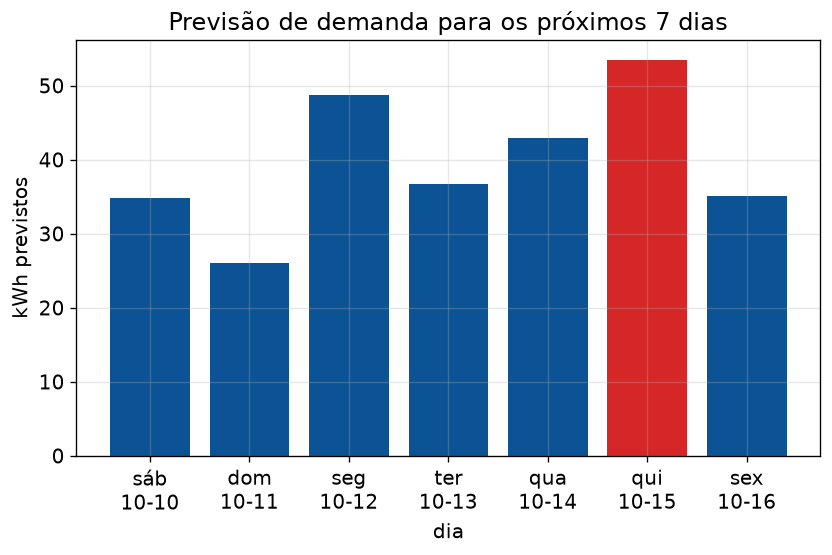

In [21]:
fig = graficos.grafico_previsao_7_dias(previsao["previsao_7_dias"])
pd.DataFrame(previsao["previsao_7_dias"])

## 5. Alertas por prioridade e conciliação com o SEMS

Os alertas entram em um heap máximo implementado à mão e saem do mais grave para o mais leve.

In [22]:
for alerta in controle_gestor.listar_alertas("10-2026"):
    print(f"[{alerta['prioridade']}] {alerta['tipo']}: {alerta['mensagem']}")

[9] INADIMPLENCIA: Apto 32: fatura 9019 de 08-2026 (R$ 176,86) vencida em 2026-10-01. Cartões da unidade bloqueados.
[8] SOBRECARGA_PREVISTA: Risco de ultrapassar 10 kW no quadro em: quinta 2026-10-15 (80%).
[7] CARTAO_BLOQUEADO: Tentativa de recarga com cartão bloqueado em 2026-10-05 19:20: D4E5F6A7 no carregador GW-002.
[6] DIVERGENCIA_SEMS: 2026-10-08 / GW-002: sessões somam 24,44 kWh e o SEMS registra 25,54 kWh (diferença de 4,3%).
[5] SESSAO_INTERROMPIDA: 1 sessão(ões) interrompida(s) em 10-2026 (ids 5273). Cobrado apenas o kWh validado até a queda.


In [23]:
linhas = []
for mes in dados.meses_com_sessoes():
    for linha in telemetria.conciliar_sems(mes):
        if linha["divergente"]:
            linhas.append(linha)
print("Dias em que a energia das sessões difere do SEMS em mais de 3%:")
pd.DataFrame(linhas)

Dias em que a energia das sessões difere do SEMS em mais de 3%:


,data,carregador,kwh_sessoes,kwh_sems,erro_absoluto,erro_relativo,divergente
0,2026-07-04,GW-002,8.43,8.85,0.42,0.0475,True
1,2026-08-06,GW-001,34.65,32.57,2.08,0.0639,True
2,2026-10-08,GW-002,24.44,25.54,1.10,0.0431,True


## 6. IA, frente 2: Síndico Virtual

Cadeia de prompts: (1) classificar a intenção com few-shot e saída em JSON, (2) executar a ferramenta local que consulta os dados, (3) redigir a resposta usando só o contexto obtido. Com a variável `OPENAI_API_KEY` definida, as etapas 1 e 3 usam o `gpt-4o-mini`; sem ela, o mesmo fluxo roda em modo simulado.

In [24]:
print("Modo atual:", controle_ia.modo_da_ia())
print()
print(sindico_virtual.PROMPT_INTENCAO)

Modo atual: simulado

Classifique a pergunta em uma das intenções: consumo_unidade, fatura_unidade, comparar_meses, anomalias, previsao_demanda, melhor_horario, status_cartao, resumo_gestor, outro.
Retorne apenas um objeto JSON válido com os campos "intencao" (string), "unidade" (string ou null) e "mes" (string no formato MM-AAAA ou null).

Pergunta: "Quanto o apto 42 consumiu em junho de 2026?"
Resposta: {"intencao": "consumo_unidade", "unidade": "Apto 42", "mes": "06-2026"}

Pergunta: "Qual o valor da fatura do apartamento 21?"
Resposta: {"intencao": "fatura_unidade", "unidade": "Apto 21", "mes": null}

Pergunta: "Teve algum problema com os carregadores este mês?"
Resposta: {"intencao": "anomalias", "unidade": null, "mes": null}

Pergunta: "Qual o melhor horário para carregar hoje?"
Resposta: {"intencao": "melhor_horario", "unidade": null, "mes": null}

Pergunta: "PERGUNTA_DO_USUARIO"
Resposta:


In [25]:
perguntas = ["Quanto o apto 42 consumiu em junho?",
             "Qual o valor da fatura do apto 21 em setembro?",
             "Por que a conta do apto 21 subiu?",
             "Teve algum problema este mês?",
             "Qual a previsão de demanda para os próximos dias?",
             "O cartão do apto 32 está bloqueado?"]
for pergunta in perguntas:
    resultado = controle_ia.perguntar(pergunta, 0, [])
    print("Pergunta:", pergunta)
    print("Intenção:", resultado["intencao"])
    print("Resposta:", resultado["resposta"])
    print()

Pergunta: Quanto o apto 42 consumiu em junho?
Intenção: consumo_unidade
Resposta: Apto 42 fez 6 recarga(s) em 06-2026, somando 120,00 kWh. Com a tarifa de R$ 0,95/kWh, o consumo é de R$ 114,00.

Pergunta: Qual o valor da fatura do apto 21 em setembro?
Intenção: fatura_unidade
Resposta: Fatura 9030 de Apto 21 em 09-2026: 247,64 kWh x R$ 0,95, sem taxa administrativa, total de R$ 235,26. Situação: paga.

Pergunta: Por que a conta do apto 21 subiu?
Intenção: comparar_meses
Resposta: Em 08-2026 Apto 21 fez 15 recarga(s) e consumiu 234,07 kWh (R$ 222,37). Em 09-2026 foram 15 recarga(s) e 247,64 kWh (R$ 235,26). O consumo subiu 13,57 kWh, diferença de R$ 12,89. Como a tarifa é a mesma, a variação vem da quantidade de energia recarregada.

Pergunta: Teve algum problema este mês?
Intenção: anomalias
Resposta: Há 5 alerta(s). Os mais graves:
- Apto 32: fatura 9019 de 08-2026 (R$ 176,86) vencida em 2026-10-01. Cartões da unidade bloqueados.
- Risco de ultrapassar 10 kW no quadro em: quinta 2026-

O contexto que a ferramenta entrega ao modelo de linguagem é um dicionário com os dados do sistema. É esse JSON que entra no prompt de resposta.

In [26]:
resultado = controle_ia.perguntar("Qual o valor da fatura do apto 42 em junho?", 0, [])
resultado["contexto"]

{'unidade': 'Apto 42',
 'mes': '06-2026',
 'fechado': True,
 'fatura': 9001,
 'kwh': 120.0,
 'tarifa': 0.95,
 'taxa_admin': 0.0,
 'valor': 114.0,
 'status': 'PAID',
 'vencimento': '2026-07-31',
 'sessoes': 6,
 'auditoria_confere': True}

## 7. Indicadores definidos na Sprint 1

A precisão do faturamento é medida auditando todas as faturas fechadas. Disponibilidade e erro de leitura RFID dependem de operação real e não são medidos no protótipo.

In [27]:
pd.DataFrame(controle_gestor.indicadores_da_sprint1())

,indicador,meta,resultado,como
0,Precisão do faturamento,100%,100%,auditoria: 32 de 32 faturas conferem com as se...
1,Precisão do modelo preditivo,> 85%,"74,3% por dia e 88,8% por semana",período de teste com dados simulados; ver Prev...
2,Disponibilidade da plataforma,> 99%,não medido,exige operação contínua em produção
3,Margem de erro de leitura RFID,< 1%,não medido,exige o leitor físico do carregador


## Conclusão

- Sessões registradas, consumo individual por unidade e rateio pela fórmula da Sprint 1, com fechamento sem taxa ou com taxa.
- Os registros de exemplo do README da Sprint 1 são reproduzidos pelo protótipo (sessão 5001 e fatura 9001 de R$ 114,00).
- A IA participa do fluxo: a previsão gera o alerta de sobrecarga e a sugestão de janela, e o Síndico Virtual responde com os dados reais do sistema.
- Os dados são simulados. A previsão diária está no teto do que essa base permite (74,3%, contra a meta de 85%) e precisa ser medida de novo com dados reais do carregador, que trazem mais histórico e informações como agendamento.